# Read me: the code here is quite messy, just look at the output classification report and figures

In [ ]:
## For some arithmetic and Matrix Operations
import numpy as np

## Dataframe Manipulation
import pandas as pd

## For Visualization
import matplotlib.pyplot as plt

## For Visualization too
import seaborn as sns

## Creating Pipeline
from sklearn.pipeline import Pipeline
from sklearn.pipeline import make_pipeline


## Creating a function transformer
from sklearn.preprocessing import FunctionTransformer

## For Column Transformer
from sklearn.compose import ColumnTransformer
from sklearn.compose import make_column_selector


## For preprocessing
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OrdinalEncoder

## For missing values
from sklearn.impute import SimpleImputer

## Getting the recall score on our train set
from sklearn.metrics import recall_score

## Getting the accuracy score on train set
from sklearn.metrics import accuracy_score

## Getting the classification report from our train set
from sklearn.metrics import classification_report

## Cross validation
from sklearn.model_selection import cross_val_score

## Gridsearch CV
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV

## Models
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

## Reading Dataset and Showing its Description

In [ ]:
from google.colab import files
uploaded = files.upload()
X = pd.read_csv('Features.csv')
y = pd.read_csv('Outcome.csv')

## Viewing the dataframe and shape
from sklearn.model_selection import train_test_split

print("Features shape:", X.shape)
print("Outcome shape:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=22, stratify=y)

# 输出训练集和测试集的形状
print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)


Saving Features.csv to Features (1).csv
Saving Outcome.csv to Outcome (1).csv
Features shape: (531916, 16)
Outcome shape: (531916, 1)
Training set shape: (372341, 16)
Test set shape: (159575, 16)


# Model Training

## 1. Creating a stratified Kfold for cross validating the test set in KNN

In [ ]:
from sklearn.model_selection import StratifiedKFold
kf = StratifiedKFold(n_splits=10,shuffle=True,random_state=22)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

2. Random Search for KNN

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import roc_auc_score
import numpy as np


knn = KNeighborsClassifier()


param_distributions = {'n_neighbors': np.random.choice([3, 5, 7, 9], size=10)}

# acc
random_search_acc = RandomizedSearchCV(knn, param_distributions=param_distributions, n_iter=10, random_state=0)
random_search_acc.fit(X_train, y_train)
y_scores_acc = random_search_acc.predict_proba(X_test)[:, 1]

print('Random Search best parameter (max. accuracy): ', random_search_acc.best_params_)
print('Random Search best score (accuracy): ', random_search_acc.best_score_)

# auc
random_search_auc = RandomizedSearchCV(knn, param_distributions=param_distributions, scoring='roc_auc', n_iter=10, random_state=0)
random_search_auc.fit(X_train, y_train)
y_scores_auc = random_search_auc.predict_proba(X_test)[:, 1]

print('Test set AUC: ', roc_auc_score(y_test, y_scores_auc))
print('Random Search best parameter (max. AUC): ', random_search_auc.best_params_)
print('Random Search best score (AUC): ', random_search_auc.best_score_)


/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:238: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:238: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:238: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:238: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for 

## 3. Classification report

In [ ]:
 import os
os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"

In [ ]:
knn = KNeighborsClassifier(n_neighbors = 5)
knn.fit(X_train, y_train)

/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:238: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


KNeighborsClassifier()

In [ ]:
y_test_pred = knn.predict(X_test)

In [ ]:
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       0.96      0.66      0.79     79787
           1       0.74      0.97      0.84     79788

    accuracy                           0.82    159575
   macro avg       0.85      0.82      0.81    159575
weighted avg       0.85      0.82      0.81    159575



## 4. visualization

### 4.1 ROC curves, Area-Under-Curve (AUC) for KNN

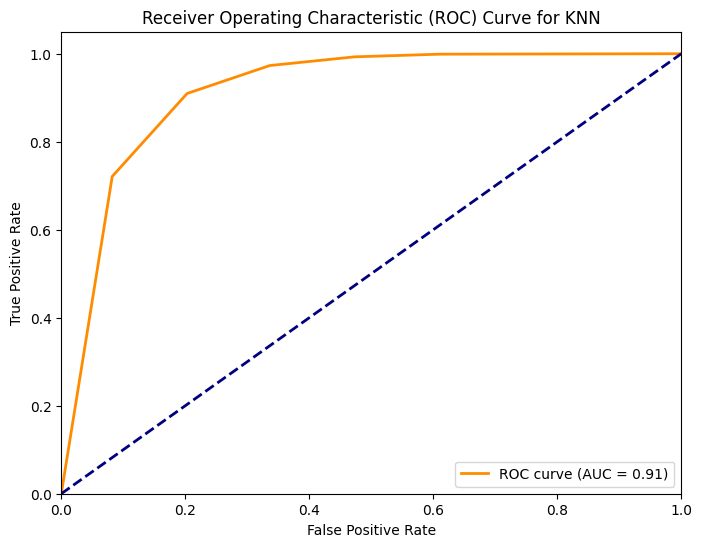

In [ ]:
from sklearn.metrics import roc_curve, auc
from sklearn.model_selection import train_test_split

y_pred_proba = knn.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

# Plot the AUC ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for KNN')
plt.legend(loc="lower right")
plt.show()

## 2.confusion matrix

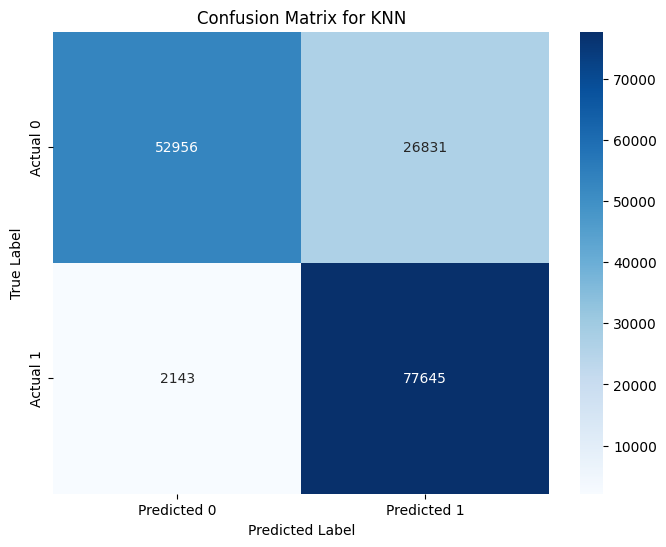

In [ ]:

from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix for KNN')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()